# Comparação MLP/LSTM/persistência — cinco minutos

Resolução real de **cinco minutos**, horizonte **t+5 minutos**. Os nomes dos arquivos foram mantidos por solicitação do usuário; o conteúdo foi migrado de diário para intradiário.

O alvo e a persistência (t−5 min) precisam ser originalmente medidos. Cada etapa de preenchimento causal usa até 15 minutos; no Brasil a combinação proxy + ffill pode atingir 30 minutos somente no histórico: nunca se interpola usando ponto posterior. Não se concatenam blocos interrompidos. A avaliação principal é diurna (elevação solar > 0); a avaliação 24h é complementar. Zero noturno não deve inflar a precisão.

As entradas principais são potência AC em p.u., hora local e dia do ano em seno/cosseno. O vento continua excluído. ERA5 nativa horária é auxiliar e não entra nos modelos principais. Estatísticas de normalização vêm apenas do treino australiano; alvos de validação/teste não ajustam escalas.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
RAIZ=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/energia_transfer').is_dir())
if str(RAIZ/'src') not in sys.path: sys.path.insert(0,str(RAIZ/'src'))
PASTA=RAIZ/'experimentos/transfer_learning_australia_brasil'
AU=RAIZ/'experimentos/australia_deep_learning'
REPORT=RAIZ/'reports/intradiario'
from energia_transfer.transfer_learning.dados import carregar,particao
_,CONFIG,CONTRATO=carregar(PASTA)
def exibir(t): display(t.round(5))


Lags selecionados somente na validação australiana. Teste não muda a escolha.


,arquitetura,lag,historico_min,selecionado_validacao,RMSE_kw_medio,RMSE_kw_dp,MAE_kw_medio,skill_persistencia_pct,R2_medio,n
0,lstm_direta,6,30,False,1.14267,0.00620,0.57064,6.67421,0.94988,63393
1,lstm_direta,12,60,True,1.13833,0.00826,0.57437,7.02856,0.95026,63393
2,mlp_direta,6,30,False,1.13922,0.00347,0.56390,6.95594,0.95018,63393
3,mlp_direta,12,60,True,1.13609,0.00673,0.56960,7.21116,0.95045,63393
4,mlp_residual,6,30,False,1.12392,0.00142,0.54103,8.20554,0.95151,63393
5,mlp_residual,12,60,True,1.12164,0.00182,0.54793,8.39164,0.95171,63393


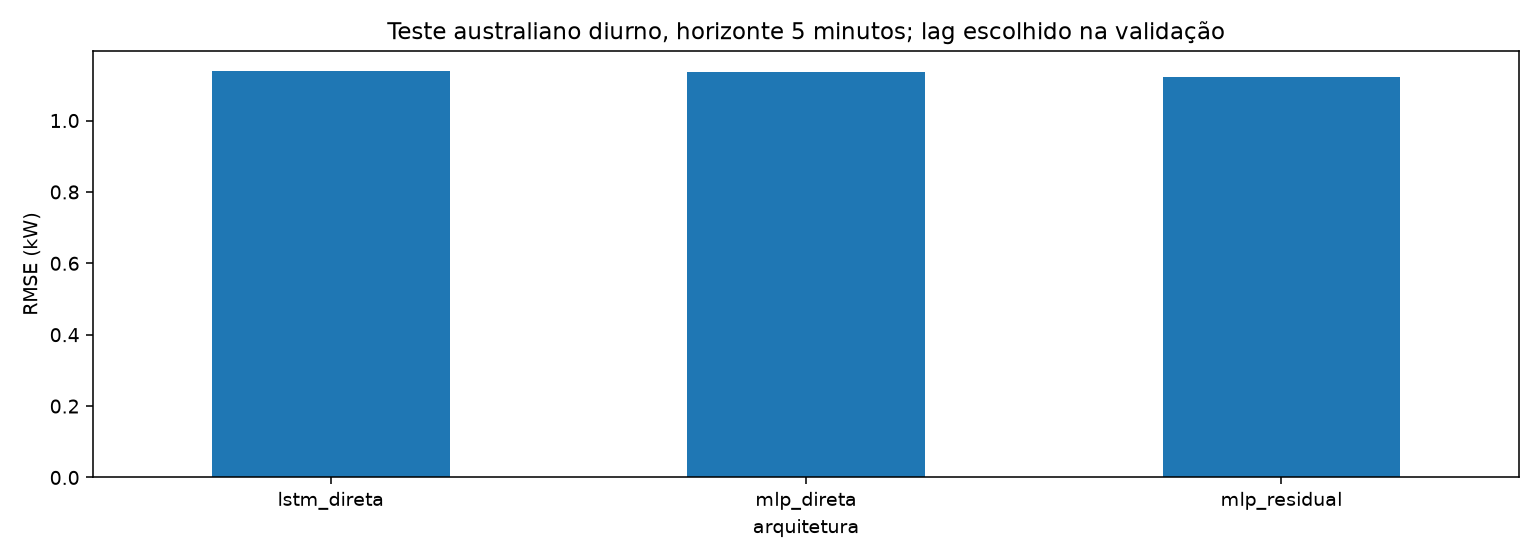

In [2]:
exibir(pd.read_csv(AU/'resultados/comparacao_modelos_5min.csv'))
display(Image(filename=str(AU/'figuras/comparacao_modelos.png')))
print('Lags selecionados somente na validação australiana. Teste não muda a escolha.')
